24/11/2026

# Exercise 1

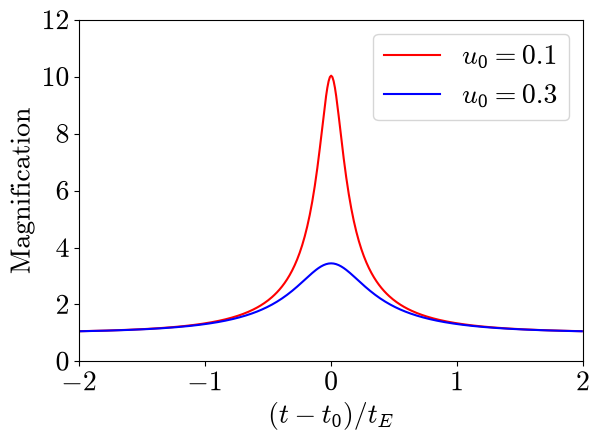

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Use Computer Modern font
plt.rcParams.update({
    'font.size': 20,
    'font.family': 'serif',
    'font.serif': ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True,
    'lines.linewidth': 2
})

# Source distance from the lens
def u(t, u0):
    return np.sqrt(u0 * u0 + t * t)

# Total amplification (magnification)
def amp(t, u0):
    u_val = u(t, u0)
    return (u_val**2 + 2.0) / (u_val * np.sqrt(u_val**2 + 4.0))

# Calculate the total amplification for the given impact parameters u0
tc = np.arange(-2.0, 2.0, 0.01)
m1 = amp(tc, 0.1) # tc = t calculated 
m2 = amp(tc, 0.3) 

# Plot the results and save the figure
plt.plot(tc, m1, 'r-', linewidth=1.5, label=r'$u_0 = 0.1$')
plt.plot(tc, m2, 'b-', linewidth=1.5, label=r'$u_0 = 0.3$')
plt.xlim(-2.0, 2.0)
plt.ylim(0.0, 12.0)
plt.xlabel(r'$(t-t_0)/t_E$')
plt.ylabel(r'$\mathrm{Magnification}$')
plt.legend()
plt.tight_layout()
plt.savefig('mlamp.png', dpi=300, bbox_inches='tight')
plt.show()


u =0.1 It passes to the clossest, it has the most amplification

# Exercise 2

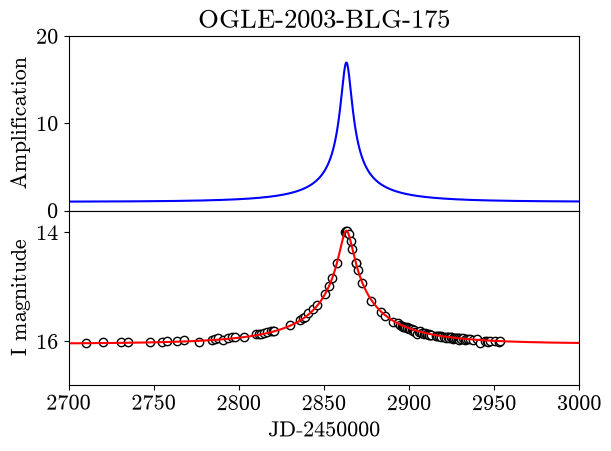

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Use Computer Modern font
plt.rcParams.update({
    'font.size': 16,
    'font.family': 'serif',
    'font.serif': ['cmr10'],
    'mathtext.fontset': 'cm',
    'axes.formatter.use_mathtext': True,
    'lines.linewidth': 2
})

# Source distance from the lens
def u(t, u0):
    return np.sqrt(u0 * u0 + t * t)

# Total amplification (magnification)
def amp(t, u0):
    u_val = u(t, u0)
    return (u_val**2 + 2.0) / (u_val * np.sqrt(u_val**2 + 4.0))

# I-band magnitude
def mi(a, ibl, fbl):
    return ibl - 2.5 * np.log10(fbl * a + 1.0 - fbl)

# Input parameters
t0 = 2452863.072
u0 = 0.059
te = 59.426
ibl = 16.046
fbl = 0.361

# Read the observed light curve
to, mo = np.loadtxt('phot.dat', unpack=True, usecols=[0, 1])

# Use reduced JD instead of full JD
t0 = t0 - 2450000.0
to = to - 2450000.0

# Calculate the total amplification and theoretical magnitude
tc = np.arange(2680.0, 3040.0, 0.1)
ac = amp((tc - t0) / te, u0)
mc = mi(ac, ibl, fbl)

# Create figure and subplots
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)

# Plot the amplification light curve
ax1.plot(tc, ac, 'b-', linewidth=1.5)
ax1.set_ylim(0.0, 20.0)
ax1.set_ylabel('Amplification')
ax1.set_title('OGLE-2003-BLG-175')

# Plot the magnitude light curve
ax2.plot(to, mo, 'ko', mfc='w')
ax2.plot(tc, mc, 'r-', linewidth=1.5)
ax2.set_xlim(2700.0, 3000.0)
ax2.set_ylim(16.8, 13.6)
ax2.set_xlabel('JD-2450000')
ax2.set_ylabel('I magnitude')

# Adjust the vertical spacing and save the figure
plt.tight_layout()
plt.subplots_adjust(hspace=0.0)
plt.savefig('OGLE-2003-BLG-175.png', dpi=300, bbox_inches='tight')
plt.show()


First the theoretical model. 
it describes very good the model. The dots are the observations in the bottom panel. 